# **THEME 1 : Communication en bande de base BPSK**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import special as sp

## **1. Canal idéal de Nyquist AWGN**

**♢ Chaîne de communication BPSK**

fonction *genBPSK*

In [2]:
# code ici
def genBPSK(N):
    symbols = np.sign(np.random.uniform(0,1,N) - 0.5)
    return symbols

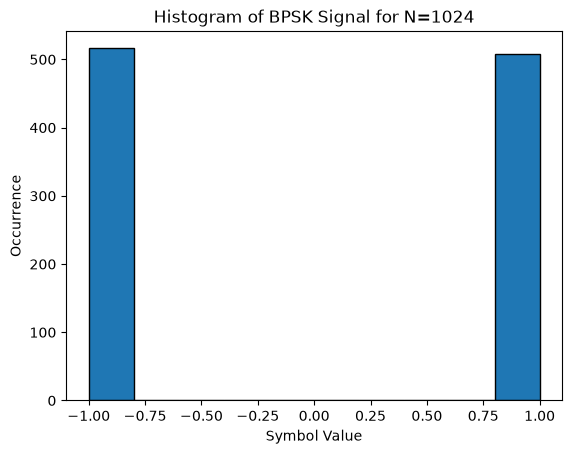

In [3]:
# tracer histogramme
a =  genBPSK(512*2)
plt.hist(a, bins=10, edgecolor='black')
plt.xlabel('Symbol Value')
plt.ylabel('Occurrence')
plt.title('Histogram of BPSK Signal for N=1024')
plt.show()

fonction *genBruitN*

In [4]:
# code ici
def genBruitN(N,sigmab):
    std = np.sqrt(sigmab)
    bruit = np.random.normal(0,std,N)
    return bruit

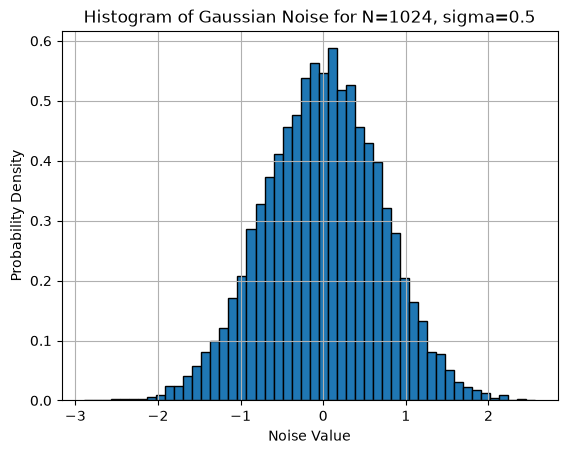

In [5]:
# tracer histogramme
sigmab = 0.5
noise = genBruitN(10000, sigmab)
plt.hist(noise, bins=50, density=True, edgecolor='black')

plt.xlabel('Noise Value')
plt.ylabel('Probability Density')
plt.title('Histogram of Gaussian Noise for N=1024, sigma=0.5')
plt.grid(True)
plt.show()

fonction *decodeBPSK*

In [6]:
# code ici
def decodeBPSK(signal_received):
    estimated_symbols = np.where(signal_received>=0,1,-1)
    return estimated_symbols

Simuler la chaîne de communication

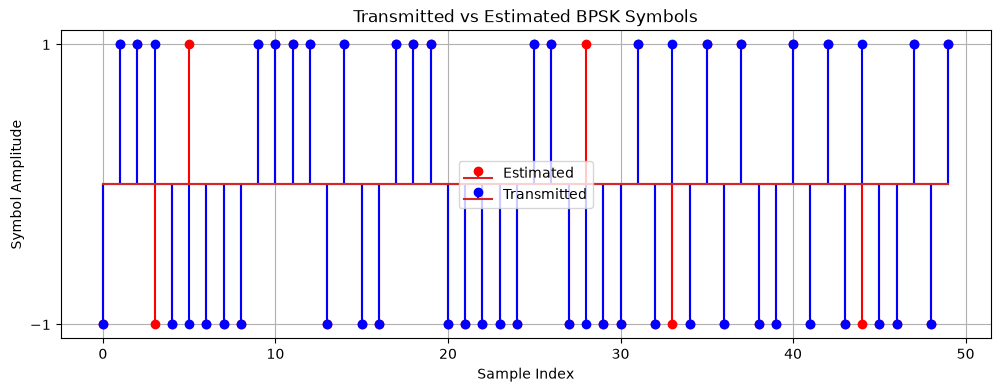

In [7]:
# Visualisez le signal BPSK modulé et estimé
N = 512
noise_variance= 0.5
g0=1

symbols= genBPSK(N)
noise = genBruitN(N, noise_variance)

signal_received = g0 * symbols + noise  #slide 28
estimated_symbols = decodeBPSK(signal_received)

plt.figure(figsize=(12, 4))
plt.stem(range(50), estimated_symbols[:50],label = "Estimated",linefmt="r")
plt.stem(range(50),symbols[:50],label="Transmitted",linefmt="b")

plt.xlabel('Sample Index')
plt.ylabel('Symbol Amplitude')
plt.title('Transmitted vs Estimated BPSK Symbols')
plt.grid(True)
plt.yticks([-1, 1])
plt.legend()
plt.show()


Quel est le taux d’erreur binaire à la réception (par simulation) ?

**Answer:** Bit error rate is all the symbols that differ from the transmitted ones divided by N.The value changes slightly at each run because N = 512 is small.

In [8]:
# code ici
BitErrorRate = np.sum(symbols != estimated_symbols) / N
print("BitErrorRate = ", BitErrorRate)

BitErrorRate =  0.07421875


**♢ Taux d’erreur binaire du canal AWGN**

Relation entre rapport signal à bruit et rapport signal à bruit normalisé :

**Answer:**
The relation between Signal-to-Noise Ratio and the Normalized Signal-to-Noise ratio is the following.

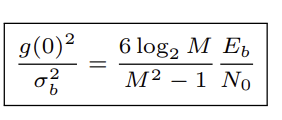


such that, for BPSK (M = 2): 6·log₂(2) / (2² − 1) = 6/3 = 2, so

$$\frac{g(0)^2}{\sigma_b^2} = \text{SNR} = 2\,\frac{E_b}{N_0} \quad\Longleftrightarrow\quad \frac{E_b}{N_0} = \frac{\text{SNR}}{2}$$

(In the first simulation, σ_b² = 0.5 and g(0) = 1, so Eb/N0 = 1, i.e. 0 dB.)



Calcul de la variance du bruit $\sigma_b^2$ pour chaque valeur $[\frac{E_b}{N_0}]_{dB}$ :

**Answer:** From the relation above: σ_b² = g0² / (2·Eb/N0), with Eb/N0 = 10^([Eb/N0]dB / 10).
The values for 0 to 12 dB are computed in the code below (0.5 at 0 dB down to ≈ 0.032 at 12 dB).

Tracer la courbe du taux d’erreur binaire

In [9]:
# code ici
N = 512
g0=1

Eb_dB = np.arange(0,13)
Eb = 10**(Eb_dB/10)

sigmab = g0**2 / (2 * Eb)

for i in range(len(Eb)):
    print(Eb_dB[i], "dB -> variance =", sigmab[i])

0 dB -> variance = 0.5
1 dB -> variance = 0.39716411736214075
2 dB -> variance = 0.3154786722400966
3 dB -> variance = 0.2505936168136362
4 dB -> variance = 0.19905358527674863
5 dB -> variance = 0.15811388300841897
6 dB -> variance = 0.125594321575479
7 dB -> variance = 0.099763115748444
8 dB -> variance = 0.07924465962305566
9 dB -> variance = 0.06294627058970835
10 dB -> variance = 0.05
11 dB -> variance = 0.03971641173621407
12 dB -> variance = 0.031547867224009665


In [10]:
# bit error rate as a function of the normalized signal-to-noise ratio (Eb/N0) in dB
N=10**6
g0=1

BitErrorRate = np.zeros(len(Eb_dB))

for i in range(len(Eb)):
    symbols = genBPSK(N)
    noise = genBruitN(N, sigmab[i])
    signal_received = g0 * symbols + noise
    estimated_symbols = decodeBPSK(signal_received)
    BitErrorRate[i] = np.sum(symbols != estimated_symbols) / N
    print('BitErrorRate for Eb/N0 =', Eb_dB[i], 'is: ', BitErrorRate[i])



BitErrorRate for Eb/N0 = 0 is:  0.078667
BitErrorRate for Eb/N0 = 1 is:  0.056562
BitErrorRate for Eb/N0 = 2 is:  0.037542
BitErrorRate for Eb/N0 = 3 is:  0.022932
BitErrorRate for Eb/N0 = 4 is:  0.0125
BitErrorRate for Eb/N0 = 5 is:  0.005843
BitErrorRate for Eb/N0 = 6 is:  0.002399
BitErrorRate for Eb/N0 = 7 is:  0.000791
BitErrorRate for Eb/N0 = 8 is:  0.000196
BitErrorRate for Eb/N0 = 9 is:  2.8e-05
BitErrorRate for Eb/N0 = 10 is:  5e-06
BitErrorRate for Eb/N0 = 11 is:  0.0
BitErrorRate for Eb/N0 = 12 is:  0.0


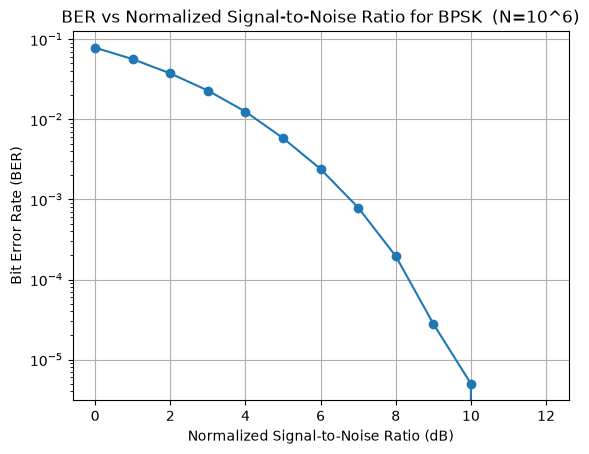

In [11]:
# The plot 
plt.figure()

plt.semilogy(Eb_dB, BitErrorRate, 'o-')

plt.xlabel('Normalized Signal-to-Noise Ratio (dB)')
plt.ylabel('Bit Error Rate (BER)')
plt.title('BER vs Normalized Signal-to-Noise Ratio for BPSK  (N=10^6)')
plt.grid(True)

plt.show()

Commenter :

**Answer:** When the normalized signal-to-noise ratio Eb/N0 increases, the bit error rate decreases, because the noise variance σ_b² decreases, so the noise pushes the received samples across the threshold 0 less often.
With N = 10⁶ the curve is smooth down to about 10 dB. At 11 dB we only get 1 error, and at 12 dB 0 errors, so the curve stops: the true error rate is not 0, N is just too small to measure it.

La valeur de N minimale pour tracer la courbe du taux d’erreur binaire pour toute la plage de $[\frac{E_b}{N_0}]_{dB}$ :

Taking the following equation of 

Pb(e)  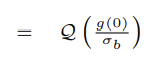


In [12]:
Pb_12dB = 0.5 * sp.erfc(np.sqrt(Eb[-1]))
N_min = 1/Pb_12dB
print("Theoretical Bit Error Rate for Eb/N0 = 12 dB is: ", Pb_12dB)
print("The minimum number of bits required for a given error rate is: ", N_min)

Theoretical Bit Error Rate for Eb/N0 = 12 dB is:  9.006010350628754e-09
The minimum number of bits required for a given error rate is:  111036958.77167019


Pb(12 dB) ≈ 9·10⁻⁹, so N_min ≈ 1/Pb ≈ 1.1·10⁸ symbols to see at least one error at 12 dB. For a reliable estimate (about 10 errors), we would need N ≈ 10/Pb ≈ 10⁹.

**Check point 1:** Bravo! appelez votre encadrant(e) pour valider



---



**♢ Probabilité d’erreur binaire théorique**

Tracer la courbe de la probabilité d’erreur binaire théorique. Vous pouvez utiliser la fonction *sp.erfc*

**From Q to erfc:**

Definitions:
$$Q(x) = \frac{1}{\sqrt{2\pi}}\int_x^{+\infty} e^{-u^2/2}\,du \qquad\qquad \text{erfc}(y) = \frac{2}{\sqrt{\pi}}\int_y^{+\infty} e^{-t^2}\,dt$$

Step 1: change of variable u = √2·t, so du = √2·dt, and u = x gives t = x/√2:
$$Q(x) = \frac{1}{\sqrt{2\pi}}\int_{x/\sqrt{2}}^{+\infty} e^{-t^2}\,\sqrt{2}\,dt = \frac{1}{\sqrt{\pi}}\int_{x/\sqrt{2}}^{+\infty} e^{-t^2}\,dt$$

Step 2: recognize erfc (multiply and divide by 2):
$$Q(x) = \frac{1}{2}\cdot\frac{2}{\sqrt{\pi}}\int_{x/\sqrt{2}}^{+\infty} e^{-t^2}\,dt = \frac{1}{2}\,\text{erfc}\left(\frac{x}{\sqrt{2}}\right)$$

Step 3: apply it to x = √(2·Eb/N0), so x/√2 = √(Eb/N0):
$$P_b = Q\left(\sqrt{\frac{2E_b}{N_0}}\right) = \frac{1}{2}\,\text{erfc}\left(\sqrt{\frac{E_b}{N_0}}\right)$$


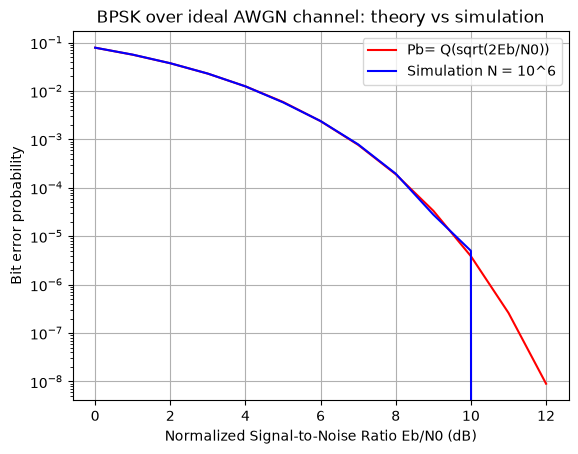

In [13]:
# code ici
Pb_theory = 0.5 * sp.erfc(np.sqrt(Eb))      # Q(sqrt(2Eb/N0)) = 0.5 erfc(sqrt(Eb/N0))

plt.figure()
plt.semilogy(Eb_dB, Pb_theory, 'r-', label='Pb= Q(sqrt(2Eb/N0))')
plt.semilogy(Eb_dB, BitErrorRate, 'b-', label='Simulation N = 10^6')
plt.xlabel('Normalized Signal-to-Noise Ratio Eb/N0 (dB)')
plt.ylabel('Bit error probability')
plt.title('BPSK over ideal AWGN channel: theory vs simulation')
plt.legend()
plt.grid(True)
plt.show()

**♢ Comparaison des courbes d’erreur : pratique et théorique**

Comparer la courbe pratique (obtenue via simulation) avec la courbe théorique. Commenter :

**Answer:** The simulated curve (N = 10⁶) lies on the theoretical curve Pb = ½·erfc(√(Eb/N0)) from 0 to about 10 dB, so the simulation is validated.
Above 10 dB the simulation is no longer reliable: only 1 error at 11 dB and 0 at 12 dB, because N = 10⁶ is smaller than N_min ≈ 1.1·10⁸.

SNR (en dB) qui permet de garantir pour une probabilité d’erreur binaire d’environ $10^{-3}$ :

In [14]:
Pb_target = 1e-3
EbN0_target = sp.erfcinv(2 * Pb_target)**2
EbN0_target_dB = 10 * np.log10(EbN0_target)
SNR_target_dB = EbN0_target_dB + 10 * np.log10(2)
print("Eb/N0 needed =", EbN0_target_dB, "dB")
print("SNR needed   =", SNR_target_dB, "dB")

Eb/N0 needed = 6.789522612404168 dB
SNR needed   = 9.79982256904398 dB


**Answer:** From ½·erfc(√(Eb/N0)) = 10⁻³ we get √(Eb/N0) = erfc⁻¹(2·10⁻³) ≈ 2.185, so Eb/N0 ≈ 4.77 ≈ 6.8 dB.
Since SNR = 2·Eb/N0, SNR ≈ 9.55 ≈ 9.8 dB (= 6.8 + 3 dB). This matches the theoretical curve, which crosses 10⁻³ at about 6.8 dB.

**Check point 2:** Bravo! appelez votre encadrant(e) pour valider



---



# **2. Interférence entre symboles (IES) et égalisation**

*fonction genSig*. Vous pouvez utiliser la fonction *lfilter*

In [15]:
from scipy.signal import lfilter
# code ici

def genSig(N):
    symbols= genBPSK(N) 
    sig = lfilter([0.5,0.2],[1],symbols) #input=symbols 
    return sig

Expression de la réponse impulsionnelle du filtre global du canal $g_n$ et $x_n$:

**Answer:** Using the Z-transform (z⁻ᵏ ↔ δ[n−k], a delay of k samples):

$$G(z) = 0.5 + 0.2\,z^{-1} \;\Longrightarrow\; g_n = 0.5\,\delta[n] + 0.2\,\delta[n-1]$$

The useful signal is the convolution of the symbols with g_n:

$$x_n = \sum_k g_k\,a_{n-k} = 0.5\,a_n + 0.2\,a_{n-1}$$

0.5·a_n is the useful part, 0.2·a_{n−1} is the interference from the previous symbol (ISI).
With a_{−1} = 0: x_0 = 0.5·a_0, x_1 = 0.5·a_1 + 0.2·a_0, x_2 = 0.5·a_2 + 0.2·a_1, …
Possible values for n ≥ 1: +0.7 (a_n = a_{n−1} = +1), +0.3 (+1, −1), −0.3 (−1, +1), −0.7 (−1, −1).


Visualiser le signal utile $x_n$

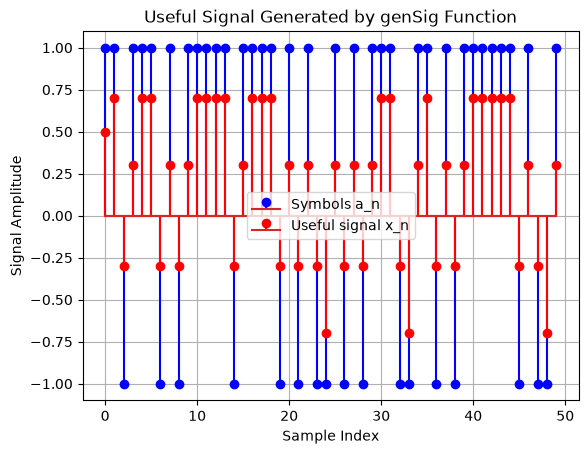

In [16]:
# code ici
N=50

useful_signal = genSig(N)
plt.figure()
plt.stem(range(N), np.sign(useful_signal), linefmt="b",label="Symbols a_n")
plt.stem(range(N), useful_signal, linefmt="r",label="Useful signal x_n")

plt.xlabel('Sample Index')
plt.ylabel('Signal Amplitude')
plt.title('Useful Signal Generated by genSig Function')
plt.legend()
plt.grid(True)
plt.show()


Commenter:

**Answer:**
- Because of the ISI, x_n no longer takes only ±1 but 4 levels: ±0.7 (two equal consecutive symbols) and ±0.3 (two opposite symbols), plus ±0.5 for the first sample.
- The sign of x_n is always the sign of a_n because 0.5 > 0.2, so without noise the decision at threshold 0 still makes no errors.
- But the distance to the threshold drops from 1 (ideal channel) to 0.3 in the worst case, so with noise these samples will cross 0 much more often, and the BER will be much higher than on the ideal channel.

**Check point 3:** Bravo! appelez votre encadrant(e) pour valider

BER of the non-ideal channel

In [17]:
N = 10**5
BER_ISI = np.zeros(len(Eb_dB))
for i in range(len(Eb_dB)):
    symbols = genBPSK(N)
    x = lfilter([0.5, 0.2], [1], symbols)      # same as genSig, but we keep the symbols
    r = x + genBruitN(N, sigmab[i])
    BER_ISI[i] = np.sum(decodeBPSK(r) != symbols) / N
    print('Eb/N0 =', Eb_dB[i], 'dB -> BER without equalization =', BER_ISI[i])

Eb/N0 = 0 dB -> BER without equalization = 0.2509
Eb/N0 = 1 dB -> BER without equalization = 0.22682
Eb/N0 = 2 dB -> BER without equalization = 0.20151
Eb/N0 = 3 dB -> BER without equalization = 0.17709
Eb/N0 = 4 dB -> BER without equalization = 0.15461
Eb/N0 = 5 dB -> BER without equalization = 0.13411
Eb/N0 = 6 dB -> BER without equalization = 0.1114
Eb/N0 = 7 dB -> BER without equalization = 0.09197
Eb/N0 = 8 dB -> BER without equalization = 0.07439
Eb/N0 = 9 dB -> BER without equalization = 0.05925
Eb/N0 = 10 dB -> BER without equalization = 0.04474
Eb/N0 = 11 dB -> BER without equalization = 0.03326
Eb/N0 = 12 dB -> BER without equalization = 0.02299


**Answer:** The BER is much higher than on the ideal channel (≈ 2·10⁻² at 12 dB instead of ≈ 9·10⁻⁹). Two reasons:
- the channel attenuates the useful part (g_0 = 0.5 instead of 1);
- the ISI puts half of the samples at ±0.3 instead of ±1, much closer to the threshold.

By hand: P_b = ½·Q(0.7/σ_b) + ½·Q(0.3/σ_b). At high SNR the Q(0.3/σ_b) term dominates, compared with Q(1/σ_b) for the ideal channel, so the loss is 20·log₁₀(1/0.3) ≈ 10.5 dB.